# Mango Leaf Disease Classification — a CNN built from scratch (PyTorch)

**Course:** 01199 Computer Vision and Pattern Recognition [B] — Fall 26-27 · Assignment

**Goal:** classify mango leaf images into **6 classes** with a basic Convolutional Neural Network trained **from scratch** (no pretrained weights).

| Class | What it is |
|---|---|
| Anthracnose | fungal disease — dark, sunken spots on the leaf |
| Bacterial Canker | bacterial disease — raised, cracked black lesions |
| Gall Midge | insect damage — small raised galls / warts |
| Healthy | no disease |
| Powdery Mildew | fungal — white powdery coating |
| Sooty Mould | fungal — black soot-like layer on the surface |

**Notebook map (each part is separate — run top to bottom with `Shift + Enter`):**

0. Setup & Google Drive (all outputs + checkpoints are saved to Drive)
1. Configuration (all hyper-parameters in one place)
2. Load the dataset & make a fixed 70 / 15 / 15 train / validation / test split
3. Explore the data
4. Build the CNN
5. Training engine with **auto-resume** checkpoints
6. Round 1 — baseline (no augmentation, no dropout, fixed LR)
7. Round 2 — regularized (augmentation + Dropout + L2 + LR scheduler)
8. Loss / accuracy curves & overfitting analysis
9. Visualize filters and feature maps
10. Evaluation — confusion matrix, classification report, misclassified & sample predictions
11. Summary of results (values for the submission form)

> **If Colab disconnects:** just reconnect and *Run all* again. Every epoch is checkpointed to Drive, so training continues from the last finished epoch instead of starting over.

## Part 0 — Setup & Google Drive

We import libraries, fix random seeds (so results are repeatable) and pick the GPU if available.
In Colab, *Runtime → Change runtime type → T4 GPU* before running.

In [1]:
# ===================== PART 0: SETUP =====================
import os, sys, json, time, random, shutil, glob

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device :", device, "-", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only (training will be slow)")

IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

PyTorch: 2.14.1+cu130
Device : cuda - Tesla T4
Running in Colab: True


In [2]:
# ===================== PART 0b: GOOGLE DRIVE =====================
# Mount Drive and locate the dataset folder `mango_original_256`.
# Expected place: My Drive/CVPR/mango_original_256  (other places are searched automatically).
# If the CVPR folder was *shared with you*, right-click it in Drive -> "Organize" -> "Add shortcut"
# and put the shortcut in "My Drive" so Colab can see it.

DATASET_NAME = "mango_original_256"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = "/content/drive/MyDrive"
else:
    DRIVE_ROOT = os.path.abspath(".")          # local run: dataset next to the notebook

def find_dataset(root, name):
    direct = [os.path.join(root, "CVPR", name), os.path.join(root, name)]
    for d in direct:
        if os.path.isdir(d):
            return d
    for depth in range(1, 4):                  # search a few folder levels deep
        pattern = os.path.join(root, *(["*"] * depth), name)
        hits = [h for h in glob.glob(pattern) if os.path.isdir(h)]
        if hits:
            return hits[0]
    return None

SRC_DIR = find_dataset(DRIVE_ROOT, DATASET_NAME)
if SRC_DIR is None:
    raise FileNotFoundError(
        f"Could not find '{DATASET_NAME}' under {DRIVE_ROOT}. "
        "Put it at My Drive/CVPR/mango_original_256 (or add a shortcut) and re-run this cell.")
print("Dataset found at:", SRC_DIR)

# All results live next to the dataset, in  CVPR/outputs/
PROJECT_DIR = os.path.dirname(SRC_DIR)
OUT_DIR  = os.path.join(PROJECT_DIR, "outputs")
CKPT_DIR = os.path.join(OUT_DIR, "checkpoints")
FIG_DIR  = os.path.join(OUT_DIR, "figures")
for d in (OUT_DIR, CKPT_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)
print("Outputs will be saved to:", OUT_DIR)

def save_fig(name):
    """Save the current matplotlib figure to Drive (PNG) before showing it."""
    path = os.path.join(FIG_DIR, name + ".png")
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("saved ->", path)

def save_json(obj, name):
    path = os.path.join(OUT_DIR, name)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)
    return path

Mounted at /content/drive
Dataset found at: /content/drive/MyDrive/CVPR/mango_original_256
Outputs will be saved to: /content/drive/MyDrive/CVPR/outputs


In [3]:
# ===================== PART 0c: COPY DATA TO THE COLAB DISK =====================
# Reading thousands of small files directly from Drive is slow, so we copy the dataset
# once to the fast local disk of the Colab machine. (Outputs still go to Drive.)
def count_images(folder):
    exts = (".jpg", ".jpeg", ".png", ".bmp")
    return sum(1 for r, _, fs in os.walk(folder) for f in fs if f.lower().endswith(exts))

if IN_COLAB:
    DATA_DIR = os.path.join("/content/data", DATASET_NAME)
    if not os.path.isdir(DATA_DIR) or count_images(DATA_DIR) != count_images(SRC_DIR):
        if os.path.isdir(DATA_DIR):
            shutil.rmtree(DATA_DIR)
        t0 = time.time()
        shutil.copytree(SRC_DIR, DATA_DIR)
        print(f"Copied dataset to local disk in {time.time() - t0:.1f}s")
else:
    DATA_DIR = SRC_DIR

print("Images on Drive :", count_images(SRC_DIR))
print("Images used     :", count_images(DATA_DIR), "from", DATA_DIR)

Copied dataset to local disk in 28.5s
Images on Drive : 2360
Images used     : 2360 from /content/data/mango_original_256


## Part 1 — Configuration

All the important settings are here, so they are easy to explain and change.

* **IMG_SIZE = 128** — images are 256×256 on disk; 128×128 keeps leaf details while training ~4× faster.
* **Round 1 (30 epochs)** is a *baseline*: no augmentation, no dropout, fixed learning rate → we expect overfitting.
* **Round 2 (60 epochs)** adds regularization: data augmentation, **Dropout (0.5)**, **L2 weight decay**, and a **cosine learning-rate scheduler**. This is the final model.
* Round 2 gets more epochs because augmented images are harder to learn from — a first 10 + 20 epoch run stopped while the model was still improving. The best epoch of each round (by validation accuracy) is saved and used.
* `SMOKE_TEST = True` runs a 1-epoch mini version just to check that everything works.

In [4]:
# ===================== PART 1: CONFIGURATION =====================
DATASET_URL = "PASTE_THE_MENDELEY_OR_DATA_IN_BRIEF_LINK_HERE"   # for the report / form

IMG_SIZE    = 128
BATCH_SIZE  = 32
VAL_FRAC    = 0.15        # 70% train / 15% validation / 15% test, split per class (stratified)
TEST_FRAC   = 0.15
NUM_WORKERS = 2

LR          = 1e-3        # Adam learning rate (both rounds start here)
MIN_LR      = 1e-5        # lowest LR reached by the cosine scheduler (Round 2)
WEIGHT_DECAY = 1e-4       # L2 regularization strength (Round 2)
DROPOUT     = 0.5         # dropout probability in the classifier (Round 2)

EPOCHS_R1   = 30          # Round 1 — baseline (long enough for overfitting to show clearly)
EPOCHS_R2   = 60          # Round 2 — regularized (the final model; augmented data needs more epochs to converge)

SMOKE_TEST    = False     # True = quick 1-epoch check on a small subset
FORCE_RETRAIN = False     # True = ignore saved checkpoints and train from scratch

if SMOKE_TEST:
    EPOCHS_R1, EPOCHS_R2 = 1, 1
    CKPT_DIR = os.path.join(OUT_DIR, "checkpoints_smoke")
    os.makedirs(CKPT_DIR, exist_ok=True)

CONFIG = dict(IMG_SIZE=IMG_SIZE, BATCH_SIZE=BATCH_SIZE, VAL_FRAC=VAL_FRAC, TEST_FRAC=TEST_FRAC, LR=LR, MIN_LR=MIN_LR,
              WEIGHT_DECAY=WEIGHT_DECAY, DROPOUT=DROPOUT, EPOCHS_R1=EPOCHS_R1, EPOCHS_R2=EPOCHS_R2,
              SEED=SEED, SMOKE_TEST=SMOKE_TEST)
save_json(CONFIG, "config.json")
print(json.dumps(CONFIG, indent=2))

{
  "IMG_SIZE": 128,
  "BATCH_SIZE": 32,
  "VAL_FRAC": 0.15,
  "TEST_FRAC": 0.15,
  "LR": 0.001,
  "MIN_LR": 1e-05,
  "WEIGHT_DECAY": 0.0001,
  "DROPOUT": 0.5,
  "EPOCHS_R1": 30,
  "EPOCHS_R2": 60,
  "SEED": 42,
  "SMOKE_TEST": false
}


## Part 2 — Load the dataset & make a fixed train / validation / test split

The dataset comes as one folder per class (no ready-made split), so we create one:

| Set | Share | Used for |
|---|---|---|
| **Train** | 70% | the CNN learns from these images (weights are updated) |
| **Validation** | 15% | checked after every epoch → curves, overfitting check, choosing the **best epoch** |
| **Test** | 15% | used **only once at the end** → final, unbiased accuracy of the chosen model |

* **Stratified** — each class is split separately, so all three sets keep the same class proportions.
* The split is **saved to Drive (`split.json`)**. If Colab restarts, the *exact same* images are used — the test set never leaks into training or model selection.
* `ImageFolder` labels every image by its folder name.

In [5]:
# ===================== PART 2: DATASET & SPLIT =====================
base_ds = datasets.ImageFolder(DATA_DIR)          # no transform: just to read file list + labels
CLASSES = base_ds.classes
NUM_CLASSES = len(CLASSES)
rel_paths = [os.path.relpath(p, DATA_DIR).replace("\\", "/") for p, _ in base_ds.samples]
targets = np.array(base_ds.targets)
print("Classes:", CLASSES)

SPLIT_PATH = os.path.join(OUT_DIR, "split.json")
split = None
if os.path.exists(SPLIT_PATH):
    with open(SPLIT_PATH) as f:
        split = json.load(f)
    if split.get("fractions") != [1 - VAL_FRAC - TEST_FRAC, VAL_FRAC, TEST_FRAC]:
        print("Saved split uses different fractions -> creating a new one.")
        split = None
    else:
        print("Loaded the saved split from Drive.")
if split is None:
    rng = np.random.default_rng(SEED)
    split = {"fractions": [1 - VAL_FRAC - TEST_FRAC, VAL_FRAC, TEST_FRAC], "train": [], "val": [], "test": []}
    for c in range(NUM_CLASSES):
        idx = np.where(targets == c)[0]
        rng.shuffle(idx)
        n_val  = int(round(len(idx) * VAL_FRAC))
        n_test = int(round(len(idx) * TEST_FRAC))
        split["test"]  += [rel_paths[i] for i in idx[:n_test]]
        split["val"]   += [rel_paths[i] for i in idx[n_test:n_test + n_val]]
        split["train"] += [rel_paths[i] for i in idx[n_test + n_val:]]
    with open(SPLIT_PATH, "w") as f:
        json.dump(split, f)
    print("Created a new stratified 70/15/15 split and saved it to Drive.")

path_to_idx = {p: i for i, p in enumerate(rel_paths)}
missing = [p for p in split["train"] + split["val"] + split["test"] if p not in path_to_idx]
assert not missing, f"{len(missing)} images in split.json are missing from the dataset (e.g. {missing[:3]})"
train_idx = [path_to_idx[p] for p in split["train"]]
val_idx   = [path_to_idx[p] for p in split["val"]]
test_idx  = [path_to_idx[p] for p in split["test"]]
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx) or set(val_idx) & set(test_idx)), "splits overlap!"

if SMOKE_TEST:   # tiny subset just to test the pipeline
    train_idx, val_idx, test_idx = train_idx[::10], val_idx[::5], test_idx[::5]

N_TRAIN, N_VAL, N_TEST = len(train_idx), len(val_idx), len(test_idx)
N_ALL = N_TRAIN + N_VAL + N_TEST
print(f"Train images     : {N_TRAIN:5d} ({N_TRAIN / N_ALL * 100:.1f}%)")
print(f"Validation images: {N_VAL:5d} ({N_VAL / N_ALL * 100:.1f}%)")
print(f"Test images      : {N_TEST:5d} ({N_TEST / N_ALL * 100:.1f}%)")
print(f"Total            : {N_ALL:5d}")

Classes: ['Anthracnose', 'Bacterial Canker', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']
Loaded the saved split from Drive.
Train images     :  1650 (69.9%)
Validation images:   355 (15.0%)
Test images      :   355 (15.0%)
Total            :  2360


In [6]:
# ----- Transforms -----
# Round 1: only resize + to-tensor (pixel values in [0, 1]).
basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

# Round 2 (training only): random variations of each image every epoch, so the CNN
# cannot memorize exact pictures. Leaves have no "up", so vertical flips are valid too.
aug_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),   # random zoom / crop
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
])

ds_plain = datasets.ImageFolder(DATA_DIR, transform=basic_transform)
ds_aug   = datasets.ImageFolder(DATA_DIR, transform=aug_transform)

train_set_plain = Subset(ds_plain, train_idx)   # Round 1 training
train_set_aug   = Subset(ds_aug,   train_idx)   # Round 2 training
val_set         = Subset(ds_plain, val_idx)     # validation and test are NEVER augmented
test_set        = Subset(ds_plain, test_idx)

loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
train_loader_plain = DataLoader(train_set_plain, shuffle=True,  **loader_kwargs)
train_loader_aug   = DataLoader(train_set_aug,   shuffle=True,  **loader_kwargs)
val_loader         = DataLoader(val_set,         shuffle=False, **loader_kwargs)
test_loader        = DataLoader(test_set,        shuffle=False, **loader_kwargs)

x, y = next(iter(train_loader_plain))
print("One batch:", tuple(x.shape), "| labels:", y[:10].tolist(), "| pixel range:", round(x.min().item(), 2), "-", round(x.max().item(), 2))

One batch: (32, 3, 128, 128) | labels: [4, 4, 4, 4, 5, 1, 3, 0, 0, 1] | pixel range: 0.0 - 1.0


## Part 3 — Explore the data

Always look at the data before training: how many images per class, and what each class looks like.

Class               Train    Val   Test  Total
Anthracnose           228     49     49    326
Bacterial Canker      366     79     79    524
Gall Midge            145     31     31    207
Healthy               222     47     47    316
Powdery Mildew        286     62     62    410
Sooty Mould           403     87     87    577
TOTAL                1650    355    355   2360
saved -> /content/drive/MyDrive/CVPR/outputs/figures/01_class_distribution.png


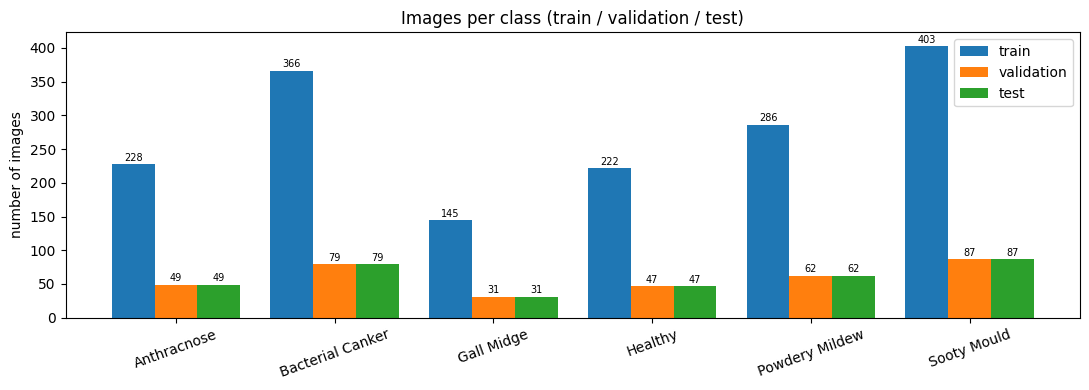

Imbalance: largest class / smallest class = 2.79x


In [7]:
# ===================== PART 3: CLASS DISTRIBUTION =====================
train_counts = np.bincount(targets[train_idx], minlength=NUM_CLASSES)
val_counts   = np.bincount(targets[val_idx],   minlength=NUM_CLASSES)
test_counts  = np.bincount(targets[test_idx],  minlength=NUM_CLASSES)
total_counts = train_counts + val_counts + test_counts

print(f"{'Class':<18}{'Train':>7}{'Val':>7}{'Test':>7}{'Total':>7}")
for c in range(NUM_CLASSES):
    print(f"{CLASSES[c]:<18}{train_counts[c]:>7}{val_counts[c]:>7}{test_counts[c]:>7}{total_counts[c]:>7}")
print(f"{'TOTAL':<18}{train_counts.sum():>7}{val_counts.sum():>7}{test_counts.sum():>7}{total_counts.sum():>7}")

xpos = np.arange(NUM_CLASSES)
plt.figure(figsize=(11, 4))
for off, counts, lab in [(-0.27, train_counts, "train"), (0.0, val_counts, "validation"), (0.27, test_counts, "test")]:
    plt.bar(xpos + off, counts, width=0.27, label=lab)
    for i in range(NUM_CLASSES):
        plt.text(xpos[i] + off, counts[i] + 5, str(counts[i]), ha="center", fontsize=7)
plt.xticks(xpos, CLASSES, rotation=20)
plt.ylabel("number of images")
plt.title("Images per class (train / validation / test)")
plt.legend()
plt.tight_layout()
save_fig("01_class_distribution")
plt.show()

print(f"Imbalance: largest class / smallest class = {total_counts.max() / total_counts.min():.2f}x")

saved -> /content/drive/MyDrive/CVPR/outputs/figures/02_sample_images.png


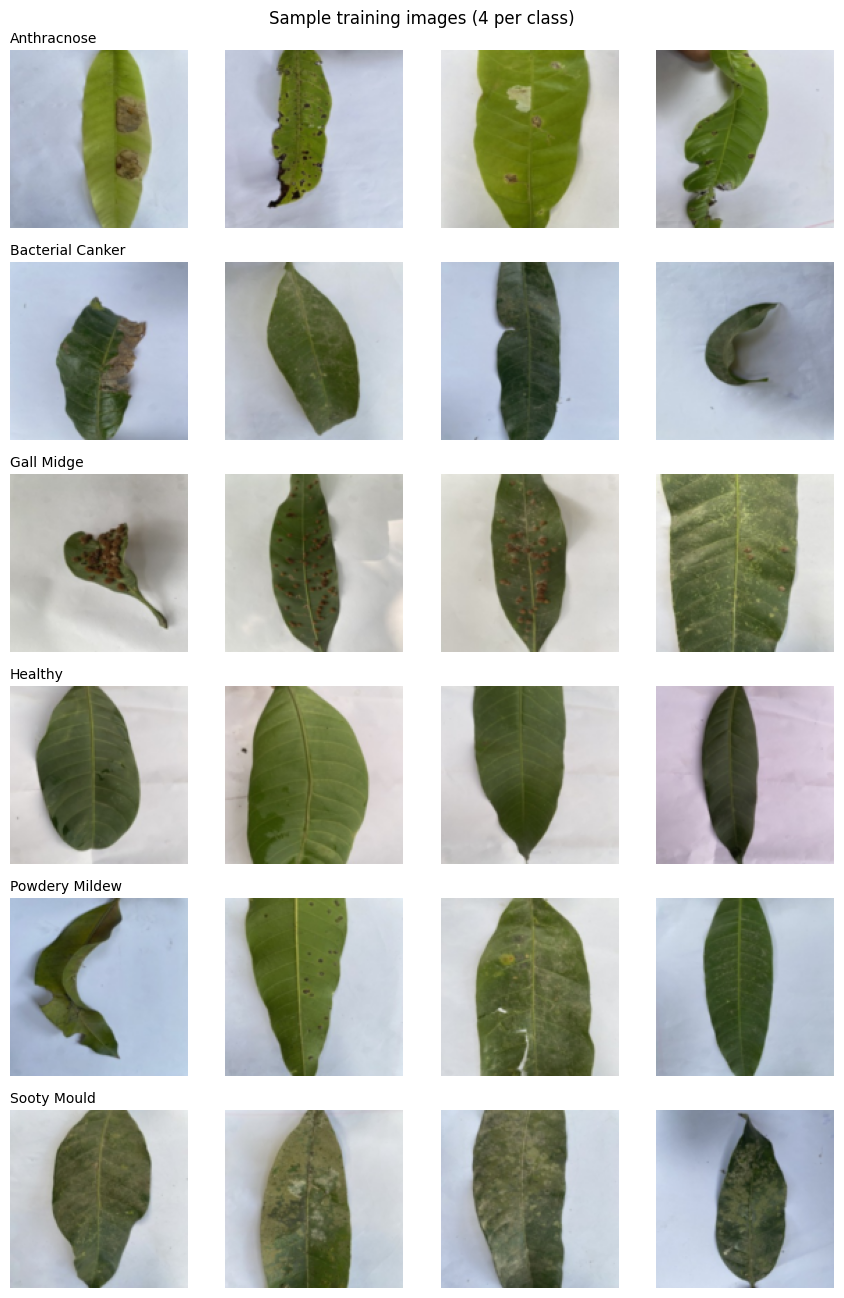

In [8]:
# ----- Sample images: 4 per class -----
n_show = 4
plt.figure(figsize=(n_show * 2.2, NUM_CLASSES * 2.2))
for c in range(NUM_CLASSES):
    cls_idx = [i for i in train_idx if targets[i] == c][:n_show]
    for j, i in enumerate(cls_idx):
        img, _ = ds_plain[i]
        plt.subplot(NUM_CLASSES, n_show, c * n_show + j + 1)
        plt.imshow(img.permute(1, 2, 0))
        plt.axis("off")
        if j == 0:
            plt.title(CLASSES[c], fontsize=10, loc="left")
plt.suptitle("Sample training images (4 per class)")
plt.tight_layout()
save_fig("02_sample_images")
plt.show()

## Part 4 — Build the CNN (from scratch)

A CNN has two parts:

**A) Feature extractor** — 4 convolution blocks. Each block is
`Conv2d (3×3 filters) → BatchNorm → ReLU → MaxPool (2×2)`.

* **Conv2d** — a set of learnable 3×3 filters that slide over the image and detect patterns (edges, spots, textures). Padding = 1 keeps the size.
* **BatchNorm** — normalizes each layer's outputs, which makes training faster and more stable.
* **ReLU** — sets negative values to 0, letting the network learn non-linear patterns.
* **MaxPool** — halves the height and width, keeping the strongest responses.
* Filters grow **32 → 64 → 128 → 128**: early layers see simple patterns, deeper layers combine them into disease-specific features (spots, powder, soot).

**B) Classifier (fully connected head)** — `Flatten → Dropout → Linear(8192→256) → ReLU → Dropout → Linear(256→6)`.

```
Input            3 × 128 × 128
Block 1 (32)  → 32 × 64 × 64
Block 2 (64)  → 64 × 32 × 32
Block 3 (128) → 128 × 16 × 16
Block 4 (128) → 128 × 8 × 8
Flatten       → 8192
FC + ReLU     → 256
FC            → 6 class scores (logits)
```

Dropout is `0.0` (off) in Round 1 and `0.5` in Round 2.

In [9]:
# ===================== PART 4: MODEL =====================
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2, 2),
    )

class MangoCNN(nn.Module):
    def __init__(self, num_classes=6, p_dropout=0.0):
        super().__init__()
        # ---- Feature extractor ----
        self.block1 = conv_block(3, 32)      # 128 -> 64
        self.block2 = conv_block(32, 64)     # 64  -> 32
        self.block3 = conv_block(64, 128)    # 32  -> 16
        self.block4 = conv_block(128, 128)   # 16  -> 8
        # ---- Classifier head ----
        self.flatten = nn.Flatten()
        self.dropout = nn.Dropout(p_dropout)
        self.fc1 = nn.Linear(128 * (IMG_SIZE // 16) * (IMG_SIZE // 16), 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.flatten(x)
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)              # raw scores; CrossEntropyLoss applies softmax

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

model_demo = MangoCNN(NUM_CLASSES).to(device)
print(model_demo)

# Trace the shape of one image through every layer
model_demo.eval()
x = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=device)
print(f"\n{'Layer':<10}{'Output shape':<22}{'Params':>10}")
print(f"{'input':<10}{str(tuple(x.shape[1:])):<22}{'':>10}")
with torch.no_grad():
    for name in ["block1", "block2", "block3", "block4", "flatten", "fc1", "fc2"]:
        layer = getattr(model_demo, name)
        x = layer(x)
        if name == "fc1":
            x = F.relu(x)
        print(f"{name:<10}{str(tuple(x.shape[1:])):<22}{count_params(layer):>10,}")

N_PARAMS = count_params(model_demo)
print(f"\nTotal trainable parameters: {N_PARAMS:,}")
del model_demo

MangoCNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block4): Sequential(
    (0): Conv2d(128,

## Part 5 — Training engine with auto-resume checkpoints

**One epoch of training:** show a batch → model predicts → **CrossEntropy loss** measures how wrong it is → **backpropagation** computes gradients → **Adam** updates the weights. After each epoch we measure loss and accuracy on the **validation set** (no weight updates there). The **test set is not touched during training**.

**Resume after disconnects** — after *every* epoch we save to Drive:
* `<run>_last.pt` — model + optimizer + scheduler + history → used to **continue** training,
* `<run>_best.pt` — the weights with the best **validation** accuracy so far (= the chosen model),
* `<run>_history.json` — the numbers behind the curves.

When the cell runs again, it loads `<run>_last.pt` and continues from the next epoch. A finished run is simply loaded, not retrained.

In [10]:
# ===================== PART 5: TRAINING ENGINE =====================
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad()
        outputs = model(imgs)                 # forward pass
        loss = criterion(outputs, labels)
        loss.backward()                       # backpropagation
        optimizer.step()                      # weight update
        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        outputs = model(imgs)
        total_loss += criterion(outputs, labels).item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

def atomic_save(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)                     # never leaves a half-written checkpoint

def load_ckpt(path):
    try:
        return torch.load(path, map_location=device, weights_only=False)
    except TypeError:                         # older PyTorch without weights_only
        return torch.load(path, map_location=device)

def run_training(run_name, model, train_loader, epochs, lr, weight_decay=0.0, use_scheduler=False):
    last_path = os.path.join(CKPT_DIR, f"{run_name}_last.pt")
    best_path = os.path.join(CKPT_DIR, f"{run_name}_best.pt")
    hist_path = os.path.join(CKPT_DIR, f"{run_name}_history.json")
    run_cfg = dict(epochs=epochs, lr=lr, weight_decay=weight_decay, use_scheduler=use_scheduler,
                   dropout=model.dropout.p, img_size=IMG_SIZE, batch_size=BATCH_SIZE,
                   n_train=len(train_loader.dataset), n_val=len(val_loader.dataset))

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)   # weight_decay = L2
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=MIN_LR) if use_scheduler else None

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": [], "time": []}
    start_epoch, best_acc = 0, -1.0

    ck = load_ckpt(last_path) if (os.path.exists(last_path) and not FORCE_RETRAIN) else None
    if ck is not None and ck.get("run_cfg") != run_cfg:
        # Settings (e.g. number of epochs) changed -> old checkpoint is not valid for this run.
        print(f"[{run_name}] settings changed since the saved checkpoint -> starting this run fresh.\n"
              f"   saved: {ck.get('run_cfg')}\n   now:   {run_cfg}")
        for p in (last_path, best_path, hist_path):
            if os.path.exists(p):
                os.remove(p)
        ck = None

    if ck is not None:
        model.load_state_dict(ck["model"])
        optimizer.load_state_dict(ck["optimizer"])
        if scheduler is not None and ck.get("scheduler") is not None:
            scheduler.load_state_dict(ck["scheduler"])
        history, start_epoch, best_acc = ck["history"], ck["epoch"], ck["best_acc"]
        if start_epoch >= epochs:
            print(f"[{run_name}] already finished ({epochs} epochs) — loaded from Drive, no retraining.")
        else:
            print(f"[{run_name}] RESUMING from epoch {start_epoch + 1}/{epochs} (best val acc so far {best_acc:.4f})")
    else:
        print(f"[{run_name}] starting fresh: {epochs} epochs")

    for epoch in range(start_epoch, epochs):
        t0 = time.time()
        lr_now = optimizer.param_groups[0]["lr"]
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = evaluate(model, val_loader, criterion)      # validation only — test set untouched
        if scheduler is not None:
            scheduler.step()
        dt = time.time() - t0

        for k, v in zip(["train_loss", "train_acc", "val_loss", "val_acc", "lr", "time"],
                        [tr_loss, tr_acc, va_loss, va_acc, lr_now, dt]):
            history[k].append(float(v))

        flag = ""
        if va_acc > best_acc:
            best_acc = va_acc
            atomic_save({"model": model.state_dict(), "epoch": epoch + 1,
                         "val_acc": va_acc, "val_loss": va_loss}, best_path)
            flag = "  <- best"
        atomic_save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                     "scheduler": scheduler.state_dict() if scheduler is not None else None,
                     "history": history, "epoch": epoch + 1, "best_acc": best_acc, "run_cfg": run_cfg}, last_path)
        with open(hist_path, "w") as f:
            json.dump(history, f)

        print(f"Epoch {epoch + 1:3d}/{epochs} | lr {lr_now:.2e} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f} | {dt:.1f}s{flag}")

    print(f"[{run_name}] best val accuracy: {max(history['val_acc']):.4f} | lowest val loss: {min(history['val_loss']):.4f}")
    return history

def load_best(model, run_name):
    ck = load_ckpt(os.path.join(CKPT_DIR, f"{run_name}_best.pt"))
    model.load_state_dict(ck["model"])
    model.eval()
    print(f"Loaded best '{run_name}' weights from epoch {ck['epoch']} (val acc {ck['val_acc']:.4f}, val loss {ck['val_loss']:.4f})")
    return model, ck["epoch"]

## Part 6 — Round 1: baseline (no augmentation, no dropout, fixed learning rate)

This is the plain CNN. With only ~1,650 training images and ~2.3 M parameters it can **memorize** the training set, so we expect training accuracy to approach 100% while validation accuracy stalls → **overfitting**.

In [11]:
# ===================== PART 6: ROUND 1 — BASELINE =====================
set_seed()
model_r1 = MangoCNN(NUM_CLASSES, p_dropout=0.0).to(device)
history_r1 = run_training("round1_baseline", model_r1, train_loader_plain,
                          epochs=EPOCHS_R1, lr=LR, weight_decay=0.0, use_scheduler=False)

[round1_baseline] settings changed since the saved checkpoint -> starting this run fresh.
   saved: {'epochs': 10, 'lr': 0.001, 'weight_decay': 0.0, 'use_scheduler': False, 'dropout': 0.0, 'img_size': 128, 'batch_size': 32, 'n_train': 1650, 'n_val': 355}
   now:   {'epochs': 30, 'lr': 0.001, 'weight_decay': 0.0, 'use_scheduler': False, 'dropout': 0.0, 'img_size': 128, 'batch_size': 32, 'n_train': 1650, 'n_val': 355}
[round1_baseline] starting fresh: 30 epochs
Epoch   1/30 | lr 1.00e-03 | train loss 2.1121 acc 0.3339 | val loss 1.7019 acc 0.2873 | 3.5s  <- best
Epoch   2/30 | lr 1.00e-03 | train loss 1.3094 acc 0.4782 | val loss 1.4635 acc 0.4141 | 3.1s  <- best
Epoch   3/30 | lr 1.00e-03 | train loss 1.1278 acc 0.5558 | val loss 1.2270 acc 0.5014 | 4.9s  <- best
Epoch   4/30 | lr 1.00e-03 | train loss 1.0000 acc 0.6079 | val loss 1.6349 acc 0.4592 | 3.1s
Epoch   5/30 | lr 1.00e-03 | train loss 0.9552 acc 0.6279 | val loss 1.9509 acc 0.3887 | 3.0s
Epoch   6/30 | lr 1.00e-03 | train loss

## Part 7 — Round 2: regularized model (the final model)

Same architecture, but we fight overfitting in four ways:

1. **Data augmentation** (training images only) — random crop/zoom, flips, rotation, colour jitter → the model sees a new variation of every leaf each epoch.
2. **Dropout (p = 0.5)** — randomly switches off half of the classifier neurons during training, so the model cannot rely on a few features.
3. **L2 regularization** — `weight_decay = 1e-4` in Adam keeps weights small (simpler model).
4. **Cosine learning-rate scheduler** — starts at 1e-3 and smoothly lowers the LR to 1e-5, so later epochs make finer adjustments.

In [12]:
# ===================== PART 7: ROUND 2 — REGULARIZED =====================
set_seed()
model_r2 = MangoCNN(NUM_CLASSES, p_dropout=DROPOUT).to(device)
history_r2 = run_training("round2_regularized", model_r2, train_loader_aug,
                          epochs=EPOCHS_R2, lr=LR, weight_decay=WEIGHT_DECAY, use_scheduler=True)

[round2_regularized] settings changed since the saved checkpoint -> starting this run fresh.
   saved: {'epochs': 20, 'lr': 0.001, 'weight_decay': 0.0001, 'use_scheduler': True, 'dropout': 0.5, 'img_size': 128, 'batch_size': 32, 'n_train': 1650, 'n_val': 355}
   now:   {'epochs': 60, 'lr': 0.001, 'weight_decay': 0.0001, 'use_scheduler': True, 'dropout': 0.5, 'img_size': 128, 'batch_size': 32, 'n_train': 1650, 'n_val': 355}
[round2_regularized] starting fresh: 60 epochs
Epoch   1/60 | lr 1.00e-03 | train loss 2.0005 acc 0.2321 | val loss 1.6760 acc 0.3155 | 7.2s  <- best
Epoch   2/60 | lr 9.99e-04 | train loss 1.6736 acc 0.2788 | val loss 1.5962 acc 0.2873 | 4.8s
Epoch   3/60 | lr 9.97e-04 | train loss 1.5959 acc 0.2873 | val loss 1.5224 acc 0.3549 | 7.1s  <- best
Epoch   4/60 | lr 9.94e-04 | train loss 1.5696 acc 0.3321 | val loss 1.4968 acc 0.3606 | 5.0s  <- best
Epoch   5/60 | lr 9.89e-04 | train loss 1.5380 acc 0.3442 | val loss 1.5241 acc 0.4085 | 5.5s  <- best
Epoch   6/60 | lr 9.

## Part 8 — Loss / accuracy curves & overfitting analysis

* **Loss** = how wrong the model is (lower is better). **Accuracy** = share of correct predictions (higher is better).
* A **growing gap** between the train and validation curves (train keeps improving, validation stalls or gets worse) means **overfitting**.

saved -> /content/drive/MyDrive/CVPR/outputs/figures/03_curves_round1.png


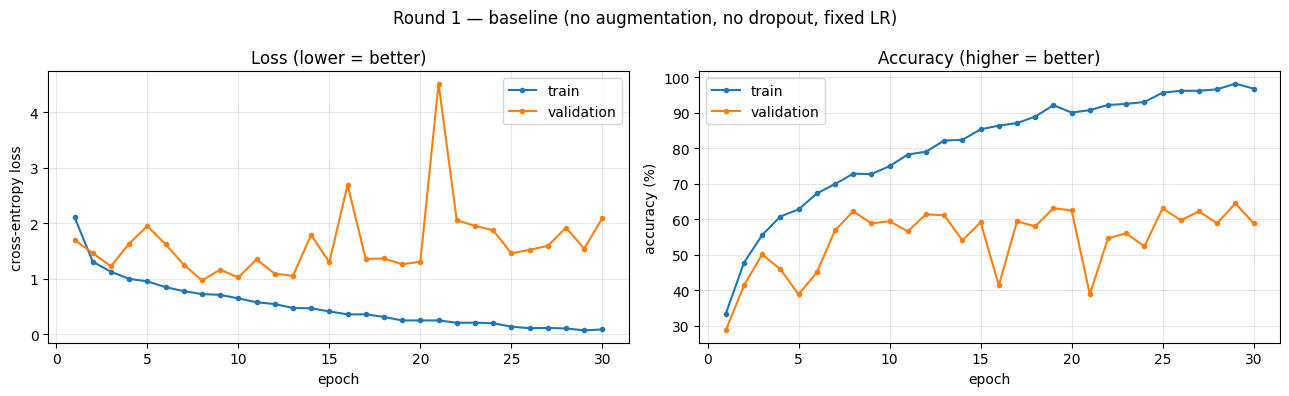

Round 1: best val acc 64.51% at epoch 29 | lowest val loss 0.9707 | final train-val accuracy gap 37.91 points


In [13]:
# ===================== PART 8: CURVES =====================
def plot_history(history, title, fname):
    ep = np.arange(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    ax1.plot(ep, history["train_loss"], "o-", ms=3, label="train")
    ax1.plot(ep, history["val_loss"],   "o-", ms=3, label="validation")
    ax1.set_title("Loss (lower = better)"); ax1.set_xlabel("epoch"); ax1.set_ylabel("cross-entropy loss")
    ax1.legend(); ax1.grid(True, alpha=0.3)
    ax2.plot(ep, np.array(history["train_acc"]) * 100, "o-", ms=3, label="train")
    ax2.plot(ep, np.array(history["val_acc"]) * 100,   "o-", ms=3, label="validation")
    ax2.set_title("Accuracy (higher = better)"); ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy (%)")
    ax2.legend(); ax2.grid(True, alpha=0.3)
    fig.suptitle(title)
    plt.tight_layout()
    save_fig(fname)
    plt.show()

def describe(history, name):
    best_ep = int(np.argmax(history["val_acc"]))
    gap = (history["train_acc"][-1] - history["val_acc"][-1]) * 100
    print(f"{name}: best val acc {history['val_acc'][best_ep] * 100:.2f}% at epoch {best_ep + 1} | "
          f"lowest val loss {min(history['val_loss']):.4f} | final train-val accuracy gap {gap:.2f} points")

plot_history(history_r1, "Round 1 — baseline (no augmentation, no dropout, fixed LR)", "03_curves_round1")
describe(history_r1, "Round 1")

saved -> /content/drive/MyDrive/CVPR/outputs/figures/04_curves_round2.png


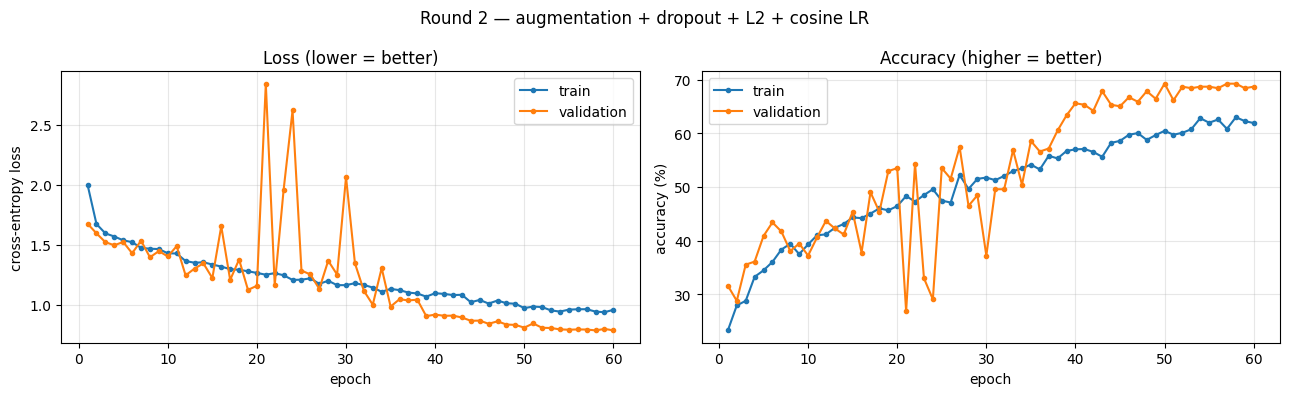

Round 2: best val acc 69.30% at epoch 50 | lowest val loss 0.7875 | final train-val accuracy gap -6.79 points


In [14]:
plot_history(history_r2, "Round 2 — augmentation + dropout + L2 + cosine LR", "04_curves_round2")
describe(history_r2, "Round 2")

saved -> /content/drive/MyDrive/CVPR/outputs/figures/05_round_comparison.png


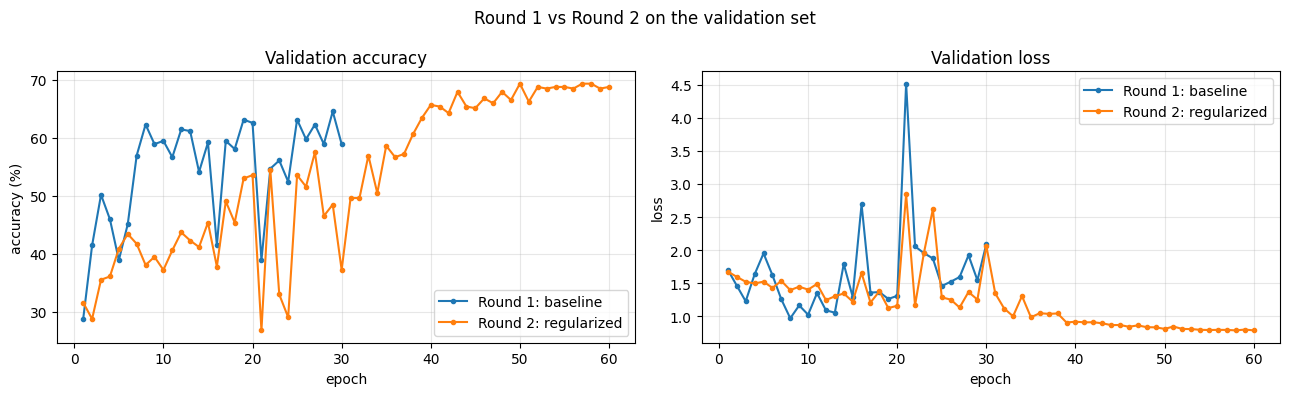

saved -> /content/drive/MyDrive/CVPR/outputs/figures/06_lr_schedule.png


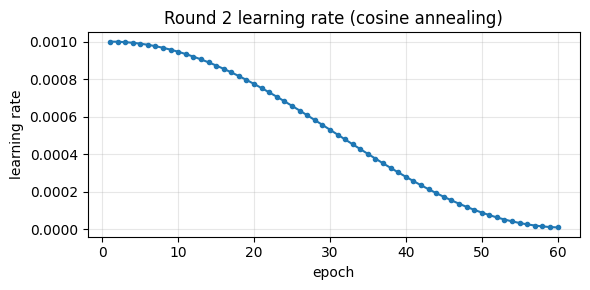

            best val acc  lowest val loss  final train acc  final val acc
Round 1           64.51%           0.9707           96.79%         58.87%
Round 2           69.30%           0.7875           61.94%         68.73%


In [15]:
# ----- Round 1 vs Round 2 -----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(np.arange(1, len(history_r1["val_acc"]) + 1), np.array(history_r1["val_acc"]) * 100, "o-", ms=3, label="Round 1: baseline")
ax1.plot(np.arange(1, len(history_r2["val_acc"]) + 1), np.array(history_r2["val_acc"]) * 100, "o-", ms=3, label="Round 2: regularized")
ax1.set_title("Validation accuracy"); ax1.set_xlabel("epoch"); ax1.set_ylabel("accuracy (%)"); ax1.legend(); ax1.grid(True, alpha=0.3)
ax2.plot(np.arange(1, len(history_r1["val_loss"]) + 1), history_r1["val_loss"], "o-", ms=3, label="Round 1: baseline")
ax2.plot(np.arange(1, len(history_r2["val_loss"]) + 1), history_r2["val_loss"], "o-", ms=3, label="Round 2: regularized")
ax2.set_title("Validation loss"); ax2.set_xlabel("epoch"); ax2.set_ylabel("loss"); ax2.legend(); ax2.grid(True, alpha=0.3)
fig.suptitle("Round 1 vs Round 2 on the validation set")
plt.tight_layout()
save_fig("05_round_comparison")
plt.show()

# Learning-rate schedule used in Round 2
plt.figure(figsize=(6, 3))
plt.plot(np.arange(1, len(history_r2["lr"]) + 1), history_r2["lr"], "o-", ms=3)
plt.title("Round 2 learning rate (cosine annealing)"); plt.xlabel("epoch"); plt.ylabel("learning rate")
plt.grid(True, alpha=0.3); plt.tight_layout()
save_fig("06_lr_schedule")
plt.show()

print(f"{'':<10}{'best val acc':>14}{'lowest val loss':>17}{'final train acc':>17}{'final val acc':>15}")
for name, h in [("Round 1", history_r1), ("Round 2", history_r2)]:
    print(f"{name:<10}{max(h['val_acc']) * 100:>13.2f}%{min(h['val_loss']):>17.4f}"
          f"{h['train_acc'][-1] * 100:>16.2f}%{h['val_acc'][-1] * 100:>14.2f}%")

### Reading the curves

* **Round 1:** training accuracy climbs towards 100% and training loss towards 0, while validation loss stops improving and usually rises again → the model is memorizing → **overfitting**.
* **Round 2:** the train and validation curves stay much closer together. Training accuracy is lower (augmented images are harder), but the model **generalizes better** to unseen leaves.

From here on we use the **best Round 2 weights** (the epoch with the highest *validation* accuracy) as the final model, and evaluate it **once** on the untouched test set.

In [16]:
# ===================== Load the best weights of both rounds =====================
model_r1, best_ep_r1 = load_best(model_r1, "round1_baseline")
model_r2, best_ep_r2 = load_best(model_r2, "round2_regularized")
final_model = model_r2

# ----- Final, one-time evaluation on the held-out TEST set -----
criterion_eval = nn.CrossEntropyLoss()
r1_test_loss, r1_test_acc = evaluate(model_r1, test_loader, criterion_eval)
test_loss, test_acc       = evaluate(final_model, test_loader, criterion_eval)
r2_val_loss, r2_val_acc   = evaluate(final_model, val_loader, criterion_eval)

print(f"\n{'Model':<22}{'best epoch':>11}{'val acc':>10}{'test acc':>10}{'test loss':>11}")
print(f"{'Round 1 (baseline)':<22}{best_ep_r1:>11}{max(history_r1['val_acc']) * 100:>9.2f}%{r1_test_acc * 100:>9.2f}%{r1_test_loss:>11.4f}")
print(f"{'Round 2 (final)':<22}{best_ep_r2:>11}{r2_val_acc * 100:>9.2f}%{test_acc * 100:>9.2f}%{test_loss:>11.4f}")

Loaded best 'round1_baseline' weights from epoch 29 (val acc 0.6451, val loss 1.5449)
Loaded best 'round2_regularized' weights from epoch 50 (val acc 0.6930, val loss 0.8106)

Model                  best epoch   val acc  test acc  test loss
Round 1 (baseline)             29    64.51%    69.58%     1.3058
Round 2 (final)                50    69.30%    74.65%     0.7194


## Part 9 — What did the CNN learn? Filters & feature maps

1. **Filters** — the 32 learned 3×3 RGB weight grids of the first convolution layer. They act as colour and edge detectors.
2. **Feature maps** — the *response* of the filters to one real leaf: bright areas show *where* a pattern was found. Early maps look like the leaf (edges, spots); the last layer's maps are small and abstract (high-level disease features).

saved -> /content/drive/MyDrive/CVPR/outputs/figures/07_conv1_filters.png


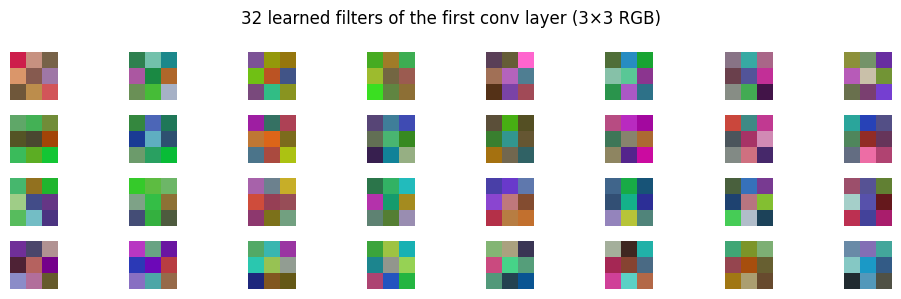

In [17]:
# ===================== PART 9: FILTERS =====================
w = final_model.block1[0].weight.detach().cpu().clone()     # [32, 3, 3, 3]
w = (w - w.min()) / (w.max() - w.min() + 1e-8)
plt.figure(figsize=(10, 3))
for i in range(w.shape[0]):
    plt.subplot(4, 8, i + 1)
    plt.imshow(w[i].permute(1, 2, 0))
    plt.axis("off")
plt.suptitle("32 learned filters of the first conv layer (3×3 RGB)")
plt.tight_layout()
save_fig("07_conv1_filters")
plt.show()

saved -> /content/drive/MyDrive/CVPR/outputs/figures/08_feature_maps_first_layer.png


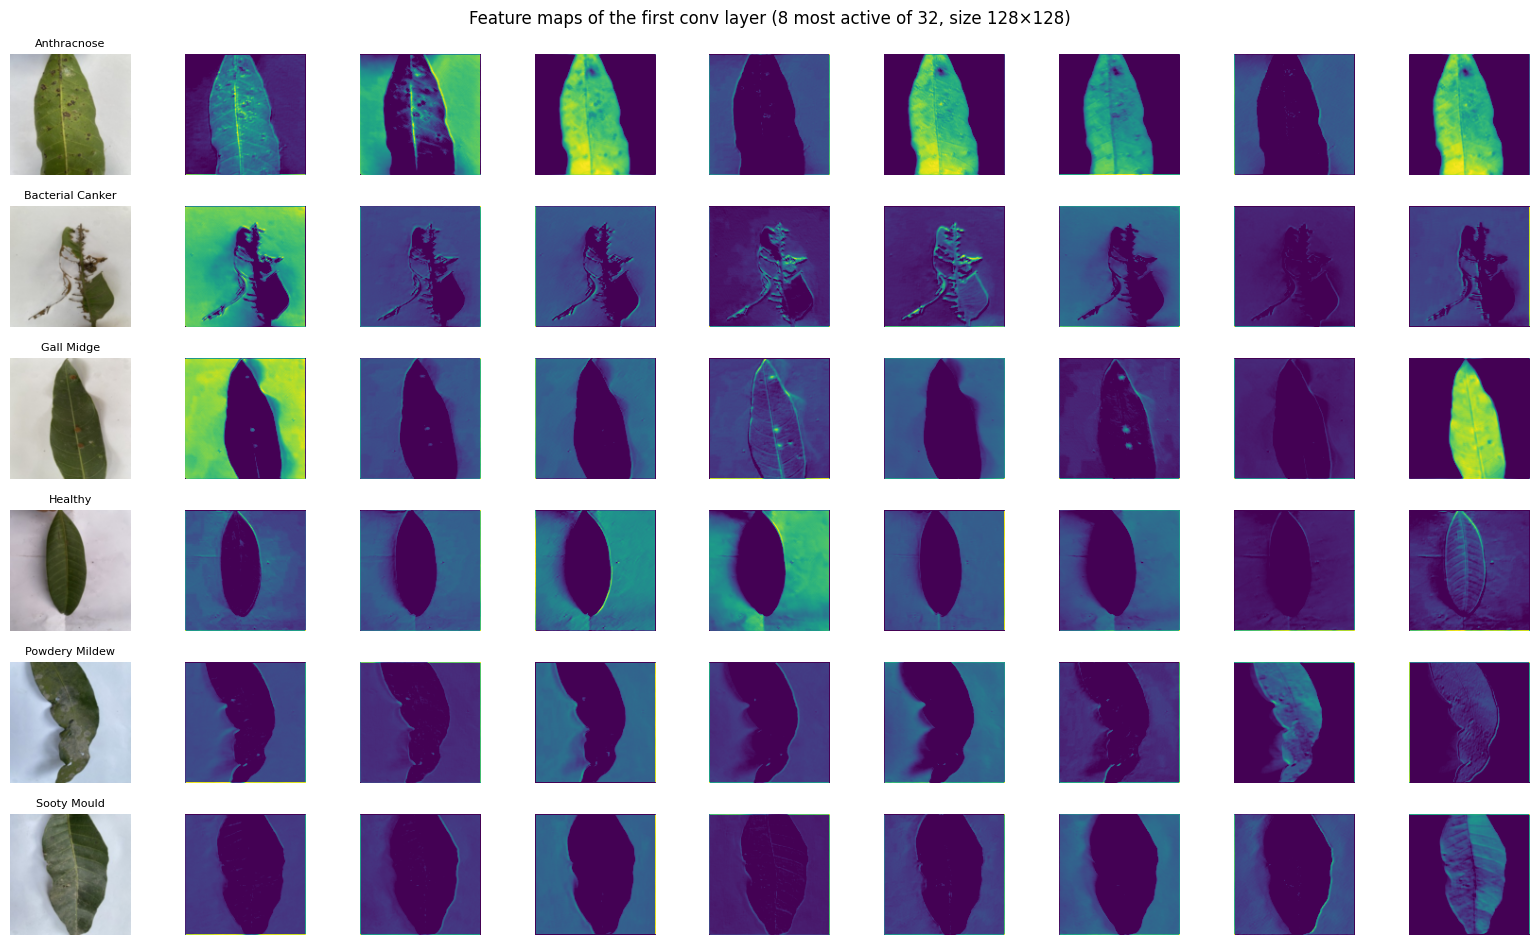

saved -> /content/drive/MyDrive/CVPR/outputs/figures/09_feature_maps_last_layer.png


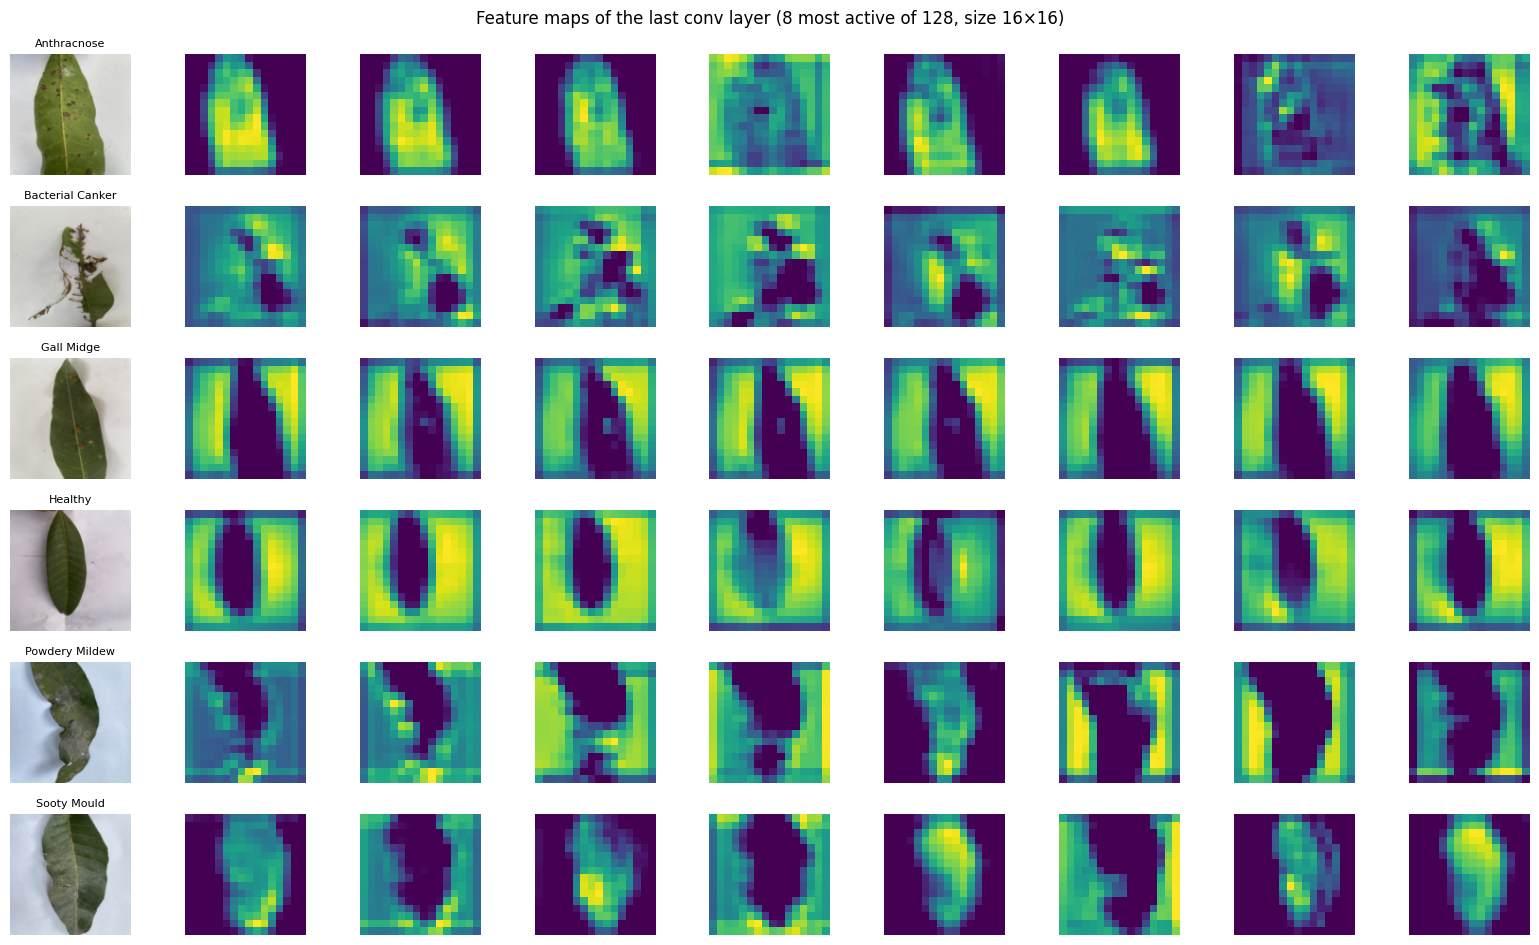

In [18]:
# ----- Feature maps for one test image of each class -----
@torch.no_grad()
def feature_maps(model, img):
    x = img.unsqueeze(0).to(device)
    first = model.block1[:3](x)                               # conv1 -> BN -> ReLU
    x = model.block3(model.block2(model.block1(x)))
    last = model.block4[:3](x)                                # conv4 -> BN -> ReLU
    return first.cpu()[0], last.cpu()[0]

final_model.eval()
example_idx = [next(i for i in test_idx if targets[i] == c) for c in range(NUM_CLASSES)]
for name, fname in [("first", "08_feature_maps_first_layer"), ("last", "09_feature_maps_last_layer")]:
    plt.figure(figsize=(16, NUM_CLASSES * 1.6))
    for r, i in enumerate(example_idx):
        img, lbl = ds_plain[i]
        fm_first, fm_last = feature_maps(final_model, img)
        fm = fm_first if name == "first" else fm_last
        plt.subplot(NUM_CLASSES, 9, r * 9 + 1)
        plt.imshow(img.permute(1, 2, 0)); plt.axis("off"); plt.title(CLASSES[lbl], fontsize=8)
        top = fm.mean(dim=(1, 2)).argsort(descending=True)[:8]   # 8 most active maps
        for j, k in enumerate(top):
            plt.subplot(NUM_CLASSES, 9, r * 9 + j + 2)
            plt.imshow(fm[k], cmap="viridis"); plt.axis("off")
    shape = tuple(fm.shape)
    plt.suptitle(f"Feature maps of the {name} conv layer (8 most active of {shape[0]}, size {shape[1]}×{shape[2]})")
    plt.tight_layout()
    save_fig(fname)
    plt.show()

## Part 10 — Evaluation on the test set

* **Confusion matrix** — rows = true class, columns = predicted class. The diagonal holds the correct predictions; anything off the diagonal shows which diseases get confused with each other.
* **Classification report** — per class:
  * **Precision** — of the leaves predicted as this class, how many really were;
  * **Recall** — of the leaves of this class, how many were found;
  * **F1** — the balance of the two.

saved -> /content/drive/MyDrive/CVPR/outputs/figures/10_confusion_matrix.png


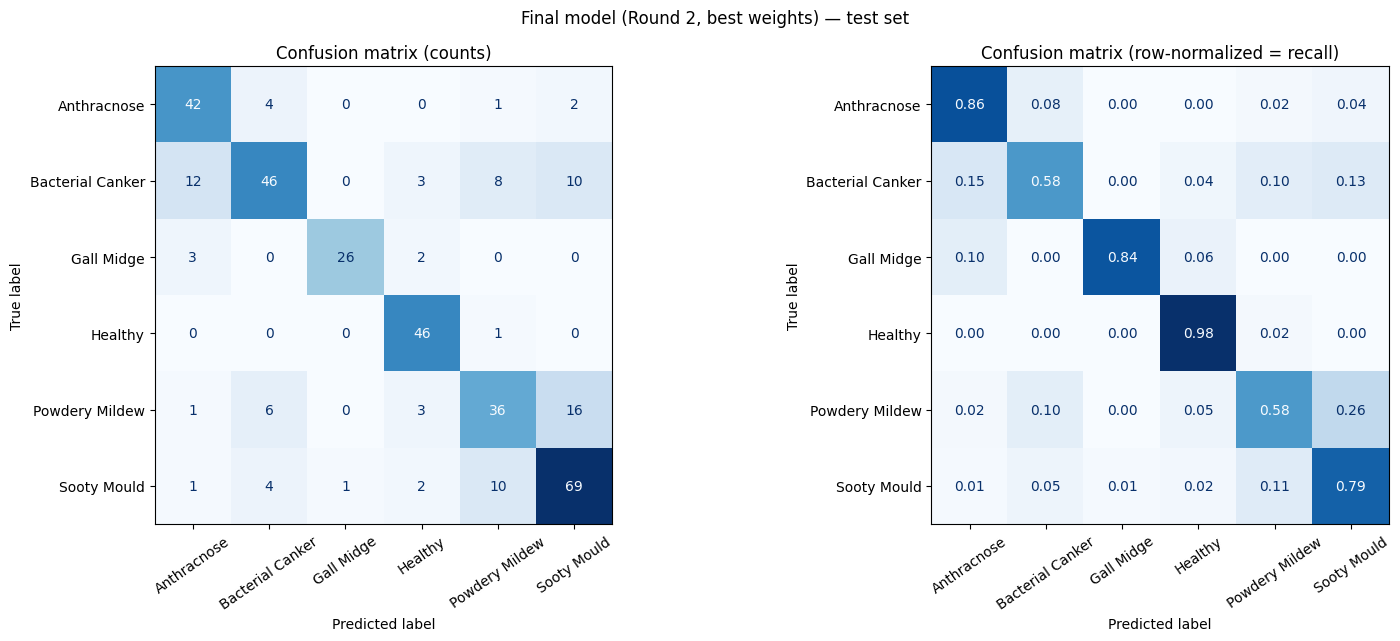

=== Final model (Round 2) ===
                  precision    recall  f1-score   support

     Anthracnose     0.7119    0.8571    0.7778        49
Bacterial Canker     0.7667    0.5823    0.6619        79
      Gall Midge     0.9630    0.8387    0.8966        31
         Healthy     0.8214    0.9787    0.8932        47
  Powdery Mildew     0.6429    0.5806    0.6102        62
     Sooty Mould     0.7113    0.7931    0.7500        87

        accuracy                         0.7465       355
       macro avg     0.7695    0.7718    0.7649       355
    weighted avg     0.7483    0.7465    0.7416       355

=== Baseline (Round 1), for comparison ===
                  precision    recall  f1-score   support

     Anthracnose     0.7347    0.7347    0.7347        49
Bacterial Canker     0.6000    0.5316    0.5638        79
      Gall Midge     0.9286    0.8387    0.8814        31
         Healthy     0.8491    0.9574    0.9000        47
  Powdery Mildew     0.5385    0.7903    0.6405      

In [19]:
# ===================== PART 10: PREDICTIONS + CONFUSION MATRIX =====================
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

@torch.no_grad()
def get_predictions(model, loader):
    model.eval()
    preds, trues, probs = [], [], []
    for imgs, labels in loader:
        out = model(imgs.to(device))
        p = F.softmax(out, dim=1).cpu()
        probs.append(p); preds.append(p.argmax(1)); trues.append(labels)
    return torch.cat(preds).numpy(), torch.cat(trues).numpy(), torch.cat(probs).numpy()

y_pred, y_true, y_prob = get_predictions(final_model, test_loader)
y_pred_r1, _, _ = get_predictions(model_r1, test_loader)
labels_all = list(range(NUM_CLASSES))

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
cm = confusion_matrix(y_true, y_pred, labels=labels_all)
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False, xticks_rotation=35)
axes[0].set_title("Confusion matrix (counts)")
cm_norm = confusion_matrix(y_true, y_pred, labels=labels_all, normalize="true")
ConfusionMatrixDisplay(cm_norm, display_labels=CLASSES).plot(ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False, xticks_rotation=35)
axes[1].set_title("Confusion matrix (row-normalized = recall)")
fig.suptitle("Final model (Round 2, best weights) — test set")
plt.tight_layout()
save_fig("10_confusion_matrix")
plt.show()

report = classification_report(y_true, y_pred, labels=labels_all, target_names=CLASSES, digits=4, zero_division=0)
report_r1 = classification_report(y_true, y_pred_r1, labels=labels_all, target_names=CLASSES, digits=4, zero_division=0)
print("=== Final model (Round 2) ===\n" + report)
print("=== Baseline (Round 1), for comparison ===\n" + report_r1)
with open(os.path.join(OUT_DIR, "classification_report.txt"), "w") as f:
    f.write("Final model (Round 2)\n" + report + "\n\nBaseline (Round 1)\n" + report_r1)

# Most confused pairs
off = [(cm[i, j], CLASSES[i], CLASSES[j]) for i in labels_all for j in labels_all if i != j and cm[i, j] > 0]
print("Most confused pairs (true -> predicted):")
for n, t, p in sorted(off, reverse=True)[:5]:
    print(f"  {t:<17} -> {p:<17} {n} images")

Misclassified: 90 of 355 test images (25.35%)
saved -> /content/drive/MyDrive/CVPR/outputs/figures/11_misclassified.png


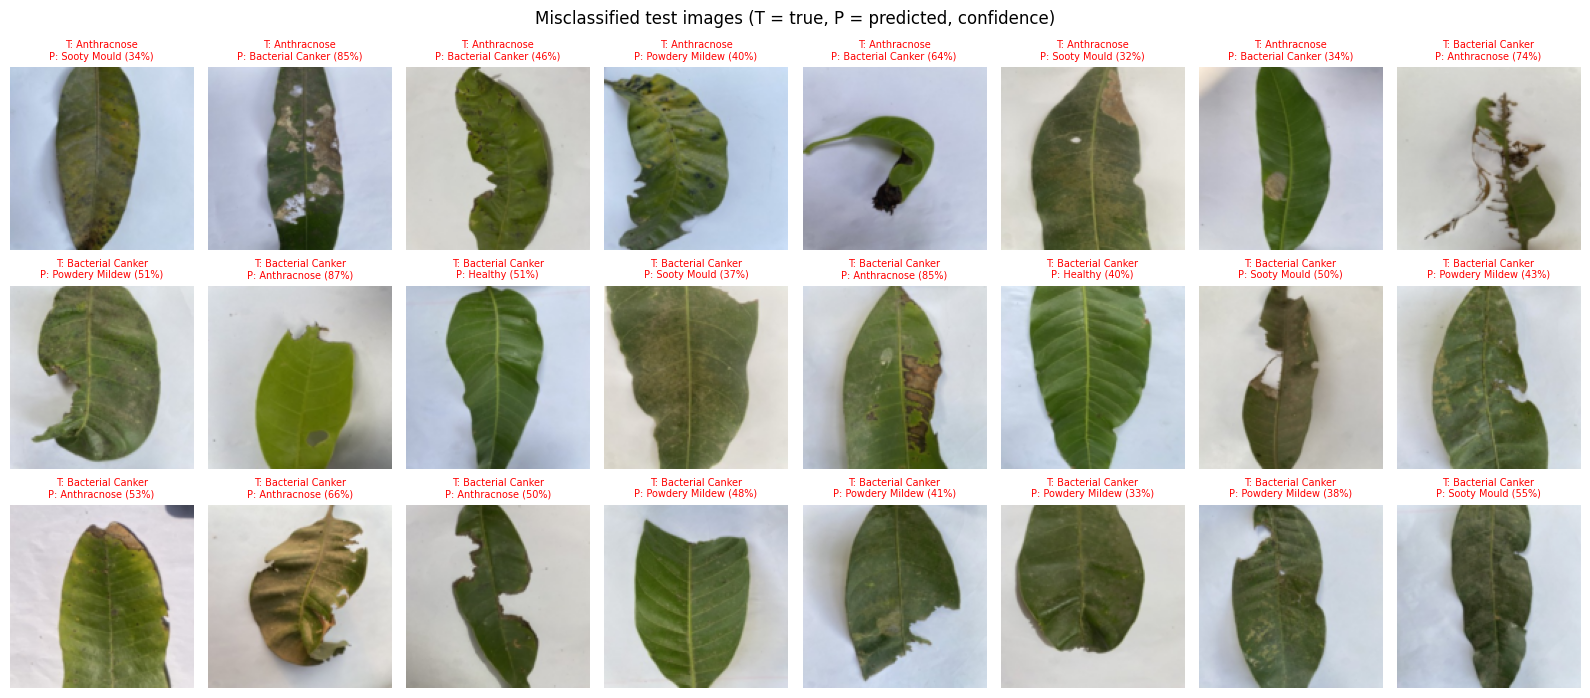

In [20]:
# ----- Misclassified test images -----
wrong = np.where(y_pred != y_true)[0]
print(f"Misclassified: {len(wrong)} of {len(y_true)} test images ({len(wrong) / len(y_true) * 100:.2f}%)")
n_show = min(24, len(wrong))
if n_show:
    cols = 8
    rows = int(np.ceil(n_show / cols))
    plt.figure(figsize=(cols * 2, rows * 2.4))
    for k, w_i in enumerate(wrong[:n_show]):
        img, _ = test_set[w_i]
        plt.subplot(rows, cols, k + 1)
        plt.imshow(img.permute(1, 2, 0)); plt.axis("off")
        plt.title(f"T: {CLASSES[y_true[w_i]]}\nP: {CLASSES[y_pred[w_i]]} ({y_prob[w_i].max() * 100:.0f}%)", fontsize=7, color="red")
    plt.suptitle("Misclassified test images (T = true, P = predicted, confidence)")
    plt.tight_layout()
    save_fig("11_misclassified")
    plt.show()

saved -> /content/drive/MyDrive/CVPR/outputs/figures/12_sample_predictions.png


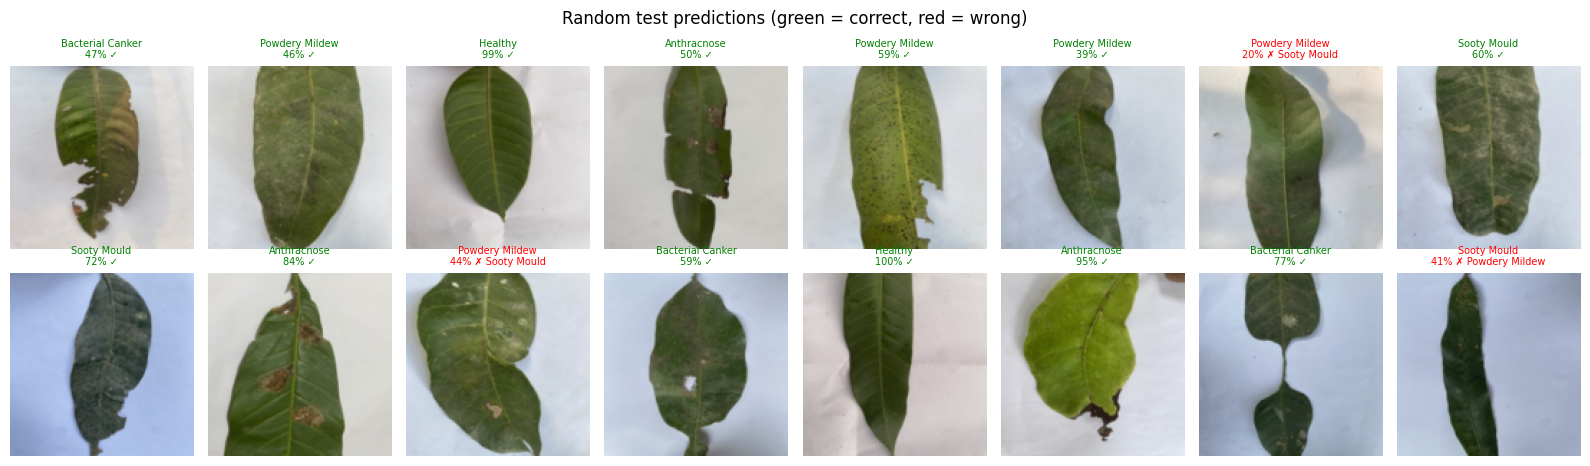

In [21]:
# ----- Random sample predictions -----
rng = np.random.default_rng(0)
pick = rng.choice(len(test_set), size=min(16, len(test_set)), replace=False)
plt.figure(figsize=(16, 4.8))
for k, i in enumerate(pick):
    img, lbl = test_set[i]
    ok = y_pred[i] == lbl
    plt.subplot(2, 8, k + 1)
    plt.imshow(img.permute(1, 2, 0)); plt.axis("off")
    plt.title(f"{CLASSES[y_pred[i]]}\n{y_prob[i].max() * 100:.0f}% {'✓' if ok else '✗ ' + CLASSES[lbl]}",
              fontsize=7, color="green" if ok else "red")
plt.suptitle("Random test predictions (green = correct, red = wrong)")
plt.tight_layout()
save_fig("12_sample_predictions")
plt.show()

## Part 11 — Summary of results (values for the submission form)

The numbers below come from the **final model (Round 2, best-validation epoch)** and are also saved to Drive as `outputs/form_summary.json`.

* *Best accuracy* / *best loss* = accuracy and loss of the final model on the **held-out test set** (evaluated once, never used for training or model selection).
* Validation numbers are listed as extra information.
* The form asks only for training and testing counts; the 15% validation images are listed separately.

In [22]:
# ===================== PART 11: FORM SUMMARY =====================
summary = {
    "6. Number of classes": NUM_CLASSES,
    "7. Dataset link": DATASET_URL,
    "8. Images used in training": N_TRAIN,
    "9. Images used in testing": N_TEST,
    "10. Best accuracy (%) [test set]": round(test_acc * 100, 2),
    "11. Best loss [test set]": round(test_loss, 4),
    "12. Epochs trained": len(history_r2["val_acc"]),
    "13. Regularization": f"Dropout (p={DROPOUT}) + L2 (weight_decay={WEIGHT_DECAY}); plus data augmentation",
    "14. Learning rate": f"Learning Rate Scheduler (CosineAnnealingLR {LR} -> {MIN_LR})",
    "15. Trainable parameters": count_params(final_model),
    "16. GitHub link": "upload this notebook (with outputs) to GitHub and paste the link",
    "(info) Validation images": N_VAL,
    "(info) Split train/val/test": f"{N_TRAIN}/{N_VAL}/{N_TEST} (70/15/15)",
    "(info) Best epoch (chosen by val acc)": best_ep_r2,
    "(info) Best val acc (%) / lowest val loss": [round(max(history_r2["val_acc"]) * 100, 2), round(min(history_r2["val_loss"]), 4)],
    "(info) Round 1 baseline test acc (%)": round(r1_test_acc * 100, 2),
    "(info) Classes": CLASSES,
}
save_json(summary, "form_summary.json")
for k, v in summary.items():
    print(f"{k:<42} {v}")

6. Number of classes                       6
7. Dataset link                            PASTE_THE_MENDELEY_OR_DATA_IN_BRIEF_LINK_HERE
8. Images used in training                 1650
9. Images used in testing                  355
10. Best accuracy (%) [test set]           74.65
11. Best loss [test set]                   0.7194
12. Epochs trained                         60
13. Regularization                         Dropout (p=0.5) + L2 (weight_decay=0.0001); plus data augmentation
14. Learning rate                          Learning Rate Scheduler (CosineAnnealingLR 0.001 -> 1e-05)
15. Trainable parameters                   2340486
16. GitHub link                            upload this notebook (with outputs) to GitHub and paste the link
(info) Validation images                   355
(info) Split train/val/test                1650/355/355 (70/15/15)
(info) Best epoch (chosen by val acc)      50
(info) Best val acc (%) / lowest val loss  [69.3, 0.7875]
(info) Round 1 baseline test acc (%) 

## Conclusion

* A **4-block CNN built from scratch** (~2.34 M parameters) learns to separate 6 mango leaf conditions from 128×128 images.
* The data is split **70 / 15 / 15** (train / validation / test). The validation set picks the best epoch; the test set is used only once, so the reported test accuracy is an unbiased estimate.
* **Round 1** (no regularization) shows clear **overfitting**: near-perfect training accuracy but a gap to the validation set.
* **Round 2** (augmentation + Dropout + L2 + cosine LR) narrows that gap and gives the best test accuracy — see the summary above.
* The confusion matrix shows which diseases look alike to the model (see the "most confused pairs" printout); these are typically diseases that both produce dark spots or patches on the leaf.

**Possible improvements:** more images for the smallest class (Gall Midge), class-weighted loss for the imbalance, a larger input size, or k-fold cross-validation for a more stable estimate.

All figures, the training histories, the checkpoints, the classification report and the form summary are saved in **`CVPR/outputs/`** on Google Drive.